# Holistic Data Preparer — Day 8
## Final Feature Engineering and Delivery

## 1. Project folders and safe file handling

Run from the project root or `notebooks/`. The notebook creates missing output folders. It reads the raw file but never overwrites it.

- `data/raw/`: original source data, preserved unchanged.
- `data/interim/`: intermediate train/test files.
- `data/processed/`: final engineered and ML-ready data.
- `reports/`: CSV reports and metadata.
- `src/`: reusable Python code.

In [1]:
from pathlib import Path
import json, warnings, ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_INTERIM = PROJECT_ROOT / "data" / "interim"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
REPORTS = PROJECT_ROOT / "reports"
SRC = PROJECT_ROOT / "src"
for folder in [DATA_RAW, DATA_INTERIM, DATA_PROCESSED, REPORTS, SRC]:
    folder.mkdir(parents=True, exist_ok=True)
print("Project root:", PROJECT_ROOT.resolve())

Project root: C:\Users\tejpa\OneDrive\Documents\R & W Projects\Data Preparing & Processing\Holistic-data-preparer


## 2. Load the same Day 1–7 dataset

Update `DAY7_CANDIDATES` if your previous notebook used a different filename. The first existing candidate is loaded. If none exists, a fixed-seed synthetic dataset is generated for demonstration only.

In [2]:
EXPECTED_COLUMNS = [
    "customer_id", "age", "gender", "region", "education_level",
    "employment_type", "annual_income", "loan_amount", "loan_purpose",
    "credit_score", "repayment_history", "transaction_count",
    "spending_ratio", "join_date", "default_flag"
]
DAY7_CANDIDATES = [
    DATA_INTERIM / "day_07_transformed.csv",
    DATA_INTERIM / "day7_transformed.csv",
    DATA_INTERIM / "Day_07_Transformed.csv",
    DATA_PROCESSED / "day_07_transformed.csv",
    DATA_INTERIM / "customer_credit_risk_day7.csv",
    DATA_RAW / "customer_credit_risk.csv",
]
dataset_path = next((p for p in DAY7_CANDIDATES if p.exists()), None)
IS_SYNTHETIC_DEMO = dataset_path is None

if dataset_path:
    df = pd.read_csv(dataset_path)
    print("Loaded existing project data:", dataset_path)
else:
    print("SYNTHETIC DEMONSTRATION DATA generated — not actual customer data.")
    rng = np.random.default_rng(RANDOM_STATE)
    n = 1200
    age = rng.integers(21, 71, n)
    income = np.clip(rng.lognormal(11.0, 0.55, n), 120000, 3500000).round()
    loan = np.clip(income * rng.uniform(0.08, 0.75, n), 10000, 1800000).round()
    score = rng.integers(300, 851, n)
    repayment = rng.choice(["Excellent", "Good", "Fair", "Poor"], n, p=[.25, .38, .25, .12])
    tx = rng.poisson(35, n)
    spend = np.clip(rng.beta(2.2, 4.0, n), .01, 1).round(3)
    repayment_effect = pd.Series(repayment).map(
        {"Excellent": -.8, "Good": -.25, "Fair": .45, "Poor": 1.1}
    ).to_numpy()
    logit = -2.2 + (650-score)/115 + repayment_effect + (loan/income)*1.8 + spend*1.2
    prob = 1/(1+np.exp(-logit))
    default = rng.binomial(1, np.clip(prob, .02, .85))
    df = pd.DataFrame({
        "customer_id": [f"CUST{i:05d}" for i in range(1, n+1)],
        "age": age,
        "gender": rng.choice(["Female", "Male", "Other"], n, p=[.46, .52, .02]),
        "region": rng.choice(["North", "South", "East", "West", "Central"], n),
        "education_level": rng.choice(["High School", "Graduate", "Postgraduate", "Other"], n),
        "employment_type": rng.choice(["Salaried", "Self-employed", "Business", "Unemployed"], n,
                                      p=[.55, .20, .18, .07]),
        "annual_income": income, "loan_amount": loan,
        "loan_purpose": rng.choice(["Home", "Personal", "Education", "Vehicle", "Business"], n),
        "credit_score": score, "repayment_history": repayment,
        "transaction_count": tx, "spending_ratio": spend,
        "join_date": pd.Timestamp("2018-01-01") + pd.to_timedelta(rng.integers(0, 3000, n), unit="D"),
        "default_flag": default
    })

if "join_date" in df:
    df["join_date"] = pd.to_datetime(df["join_date"], errors="coerce")
df["default_flag"] = pd.to_numeric(df["default_flag"], errors="coerce")
print("Data type:", "Synthetic demonstration" if IS_SYNTHETIC_DEMO else "Existing project dataset")
print("Shape:", df.shape)
display(df.head())

SYNTHETIC DEMONSTRATION DATA generated — not actual customer data.
Data type: Synthetic demonstration
Shape: (1200, 15)


,customer_id,age,gender,region,education_level,employment_type,annual_income,loan_amount,loan_purpose,credit_score,repayment_history,transaction_count,spending_ratio,join_date,default_flag
0,CUST00001,25,Male,Central,High School,Unemployed,120000.0,52104.0,Personal,626,Good,38,0.517,2023-05-03,0
1,CUST00002,59,Female,Central,Graduate,Salaried,120000.0,58001.0,Business,561,Fair,33,0.332,2022-06-10,1
2,CUST00003,53,Male,West,High School,Business,120000.0,68896.0,Business,362,Fair,29,0.874,2025-09-17,1
3,CUST00004,42,Male,East,High School,Business,120000.0,15377.0,Home,614,Good,37,0.248,2018-10-10,0
4,CUST00005,42,Male,South,Graduate,Salaried,120000.0,51061.0,Vehicle,396,Poor,38,0.201,2023-10-31,1


## 3. Schema and target validation

The target must be `default_flag`: 0 = No Default, 1 = Default. Never impute the target. Missing or invalid labels must be investigated separately.

In [3]:
missing_columns = [c for c in EXPECTED_COLUMNS if c not in df.columns]
extra_columns = [c for c in df.columns if c not in EXPECTED_COLUMNS]
schema_report = pd.DataFrame({
    "check": ["required_columns_present", "extra_columns_present", "target_present"],
    "result": [not missing_columns, bool(extra_columns), "default_flag" in df.columns],
    "details": [", ".join(missing_columns) or "All required columns found",
                ", ".join(extra_columns) or "No extra columns", "0 = No Default; 1 = Default"]
})
display(schema_report)
if missing_columns:
    raise ValueError("Missing required columns: " + ", ".join(missing_columns))
if df["default_flag"].isna().any():
    raise ValueError("Target contains missing labels. Investigate them; do not impute target.")
if not df["default_flag"].isin([0, 1]).all():
    raise ValueError("default_flag must contain only 0 and 1.")
work = df.copy()

,check,result,details
0,required_columns_present,True,All required columns found
1,extra_columns_present,False,No extra columns
2,target_present,True,0 = No Default; 1 = Default


## 4. Feature engineering

Feature engineering creates useful model inputs from existing fields.

- `loan_to_income_ratio`: loan amount divided by annual income.
- `income_per_transaction`: annual income divided by transaction count.
- `customer_tenure_days`: days between customer join date and a fixed reference date.
- `age_band`: grouped age range.
- `repayment_risk_level`: ordered mapping from repayment history (higher = poorer history).

The target is never used to create a feature. `customer_id` remains an identifier, not a predictor. A fixed reference date makes the calculation reproducible; in a live system, use the actual prediction/observation date.

In [4]:
REFERENCE_DATE = pd.Timestamp("2026-01-01")
for col in ["age", "annual_income", "loan_amount", "credit_score",
            "transaction_count", "spending_ratio"]:
    work[col] = pd.to_numeric(work[col], errors="coerce")

income_denominator = work["annual_income"].where(work["annual_income"] > 0)
transaction_denominator = work["transaction_count"].where(work["transaction_count"] > 0)
work["loan_to_income_ratio"] = work["loan_amount"] / income_denominator
work["income_per_transaction"] = work["annual_income"] / transaction_denominator
work["customer_tenure_days"] = (
    REFERENCE_DATE - pd.to_datetime(work["join_date"], errors="coerce")
).dt.days
work.loc[work["customer_tenure_days"] < 0, "customer_tenure_days"] = np.nan
work["age_band"] = pd.cut(
    work["age"], bins=[0, 25, 35, 50, 65, np.inf],
    labels=["18-25", "26-35", "36-50", "51-65", "66+"]
)
work["repayment_risk_level"] = work["repayment_history"].map(
    {"Excellent": 0, "Good": 1, "Fair": 2, "Poor": 3}
)
engineered_features = [
    "loan_to_income_ratio", "income_per_transaction", "customer_tenure_days",
    "age_band", "repayment_risk_level"
]
display(work[EXPECTED_COLUMNS + engineered_features].head())

,customer_id,age,gender,region,education_level,employment_type,annual_income,loan_amount,loan_purpose,credit_score,repayment_history,transaction_count,spending_ratio,join_date,default_flag,loan_to_income_ratio,income_per_transaction,customer_tenure_days,age_band,repayment_risk_level
0,CUST00001,25,Male,Central,High School,Unemployed,120000.0,52104.0,Personal,626,Good,38,0.517,2023-05-03,0,0.434200,3157.894737,974.0,18-25,1
1,CUST00002,59,Female,Central,Graduate,Salaried,120000.0,58001.0,Business,561,Fair,33,0.332,2022-06-10,1,0.483342,3636.363636,1301.0,51-65,2
2,CUST00003,53,Male,West,High School,Business,120000.0,68896.0,Business,362,Fair,29,0.874,2025-09-17,1,0.574133,4137.931034,106.0,51-65,2
3,CUST00004,42,Male,East,High School,Business,120000.0,15377.0,Home,614,Good,37,0.248,2018-10-10,0,0.128142,3243.243243,2640.0,36-50,1
4,CUST00005,42,Male,South,Graduate,Salaried,120000.0,51061.0,Vehicle,396,Poor,38,0.201,2023-10-31,1,0.425508,3157.894737,793.0,36-50,3


### 4.1 Review engineered features

A zero or invalid denominator can create missing ratio values. Those values are not automatically errors; the later training pipeline imputes them using training data only. Extreme values should be investigated using business context rather than removed automatically.

In [5]:
display(work[engineered_features].describe(include="all").T)
engineering_report = pd.DataFrame({
    "feature": engineered_features,
    "definition": [
        "Loan amount / annual income",
        "Annual income / transaction count",
        "Days from join date to reference date",
        "Age grouped into readable bands",
        "Repayment history mapped from 0 (Excellent) to 3 (Poor)"
    ],
    "missing_count": [int(work[c].isna().sum()) for c in engineered_features],
    "missing_percent": [float(work[c].isna().mean()*100) for c in engineered_features]
})
display(engineering_report)
engineering_report.to_csv(REPORTS / "day_08_feature_engineering_report.csv", index=False)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
loan_to_income_ratio,1200.0,NaN,NaN,NaN,0.411723,0.194432,0.083254,0.243969,0.412854,0.581065,0.749842
income_per_transaction,1200.0,NaN,NaN,NaN,3663.284855,828.921355,2264.150943,3157.894737,3529.411765,4000.0,9989.869565
customer_tenure_days,1169.0,NaN,NaN,NaN,1498.856287,842.854565,1.0,772.0,1537.0,2214.0,2919.0
age_band,1200,5,36-50,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
repayment_risk_level,1200.0,NaN,NaN,NaN,1.189167,0.942049,0.0,0.0,1.0,2.0,3.0


,feature,definition,missing_count,missing_percent
0,loan_to_income_ratio,Loan amount / annual income,0,0.000000
1,income_per_transaction,Annual income / transaction count,0,0.000000
2,customer_tenure_days,Days from join date to reference date,31,2.583333
3,age_band,Age grouped into readable bands,0,0.000000
4,repayment_risk_level,Repayment history mapped from 0 (Excellent) to...,0,0.000000


## 5. Feature selection

- Exclude `customer_id` because it is an identifier and may encourage memorization.
- Exclude `default_flag` from X because it is the prediction target.
- Exclude raw `join_date` after deriving tenure.
- Keep meaningful financial, behavioral, and engineered predictors.

**Fairness and compliance note:** Gender, region, and education may be sensitive or restricted in real lending decisions. They are included here only to demonstrate categorical preprocessing. A production credit model requires legal, privacy, fairness, and domain review; remove protected or inappropriate attributes as required.

In [6]:
TARGET = "default_flag"
IDENTIFIER = "customer_id"
numeric_features = [
    "age", "annual_income", "loan_amount", "credit_score",
    "transaction_count", "spending_ratio", "loan_to_income_ratio",
    "income_per_transaction", "customer_tenure_days", "repayment_risk_level"
]
categorical_features = [
    "gender", "region", "education_level", "employment_type",
    "loan_purpose", "repayment_history", "age_band"
]
model_features = numeric_features + categorical_features
feature_selection_report = pd.DataFrame({
    "column": work.columns,
    "role": [
        "Identifier — excluded" if c == IDENTIFIER else
        "Target — separate y" if c == TARGET else
        "Raw date — excluded after tenure feature" if c == "join_date" else
        "Model predictor" if c in model_features else "Review / not selected"
        for c in work.columns
    ]
})
display(feature_selection_report)
feature_selection_report.to_csv(REPORTS / "day_08_feature_selection_report.csv", index=False)
assert TARGET not in model_features and IDENTIFIER not in model_features

,column,role
0,customer_id,Identifier — excluded
1,age,Model predictor
2,gender,Model predictor
3,region,Model predictor
4,education_level,Model predictor
5,employment_type,Model predictor
6,annual_income,Model predictor
7,loan_amount,Model predictor
8,loan_purpose,Model predictor
9,credit_score,Model predictor


## 6. Final data validation

These checks identify suspicious records; they do not automatically delete them. Confirm business definitions before changing unusual values.

In [7]:
checks = []
def add_check(name, passed, details):
    checks.append({"check": name, "passed": bool(passed), "details": str(details)})

add_check("Target is binary", work[TARGET].isin([0, 1]).all(), "Only 0 and 1 allowed")
add_check("Both target classes exist", work[TARGET].nunique() == 2, f"Classes: {sorted(work[TARGET].unique())}")
add_check("Customer IDs are unique", not work[IDENTIFIER].duplicated().any(),
          f"Duplicate IDs: {int(work[IDENTIFIER].duplicated().sum())}")
add_check("Age range reviewed", work["age"].dropna().between(18, 100).all(), "Expected review range 18–100")
add_check("Income is non-negative", (work["annual_income"].dropna() >= 0).all(), "Negative values require investigation")
add_check("Loan amount is non-negative", (work["loan_amount"].dropna() >= 0).all(), "Negative values require investigation")
add_check("Credit score reviewed", work["credit_score"].dropna().between(300, 900).all(),
          "Confirm the source credit-score definition")
add_check("Spending ratio reviewed", work["spending_ratio"].dropna().between(0, 1).all(),
          "Expected ratio range 0–1; verify source definition")
add_check("All model features exist", set(model_features).issubset(work.columns), "Required predictors exist")
validation_report = pd.DataFrame(checks)
display(validation_report)
validation_report.to_csv(REPORTS / "day_08_final_validation_report.csv", index=False)
if not validation_report["passed"].all():
    warnings.warn("Some validation checks failed. Review the CSV report before delivery.")

,check,passed,details
0,Target is binary,True,Only 0 and 1 allowed
1,Both target classes exist,True,"Classes: [np.int64(0), np.int64(1)]"
2,Customer IDs are unique,True,Duplicate IDs: 0
3,Age range reviewed,True,Expected review range 18–100
4,Income is non-negative,True,Negative values require investigation
5,Loan amount is non-negative,True,Negative values require investigation
6,Credit score reviewed,True,Confirm the source credit-score definition
7,Spending ratio reviewed,True,Expected ratio range 0–1; verify source defini...
8,All model features exist,True,Required predictors exist


## 7. Create the final feature table and split the data

Split before fitting any imputer, encoder, or scaler. This prevents test-set information from influencing learned preprocessing.

The audit table keeps customer ID and target for traceability. The model's X matrix excludes both. The train/test raw-feature CSVs are interim files; transformations are fitted inside the pipeline using training rows only.

A random stratified split is a baseline. For a real time-dependent credit-risk task, a chronological split may better represent future predictions.

In [8]:
audit_columns = [IDENTIFIER] + model_features + [TARGET]
final_feature_table = work[audit_columns].copy()
X = final_feature_table[model_features].copy()
y = final_feature_table[TARGET].astype(int).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Feature table:", final_feature_table.shape)
print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Train target proportions:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())
print("Test target proportions:")
display(y_test.value_counts(normalize=True).rename("proportion").to_frame())

final_feature_table.to_csv(DATA_PROCESSED / "day_08_feature_engineered.csv", index=False)
X_train.assign(default_flag=y_train).to_csv(DATA_INTERIM / "day_08_train_raw_features.csv", index=False)
X_test.assign(default_flag=y_test).to_csv(DATA_INTERIM / "day_08_test_raw_features.csv", index=False)

Feature table: (1200, 19)
Train rows: 960 | Test rows: 240
Train target proportions:


,proportion
default_flag,
0,0.596875
1,0.403125


Test target proportions:


,proportion
default_flag,
0,0.595833
1,0.404167


## 8. Leakage-safe preprocessing and baseline model

The pipeline learns:
1. Numeric median imputation.
2. Numeric standard scaling.
3. Categorical most-frequent imputation.
4. One-hot encoding with unseen-category protection.
5. Logistic regression.

Because preprocessing is inside the pipeline, `fit` is called only on training data. The test set is only transformed and evaluated.

In [9]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])
credit_risk_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced",
                                      random_state=RANDOM_STATE))
])
credit_risk_pipeline.fit(X_train, y_train)
predictions = credit_risk_pipeline.predict(X_test)
probabilities = credit_risk_pipeline.predict_proba(X_test)[:, 1]

metrics = pd.DataFrame([{
    "accuracy": accuracy_score(y_test, predictions),
    "precision": precision_score(y_test, predictions, zero_division=0),
    "recall": recall_score(y_test, predictions, zero_division=0),
    "f1_score": f1_score(y_test, predictions, zero_division=0),
    "roc_auc": roc_auc_score(y_test, probabilities) if y_test.nunique() == 2 else np.nan
}])
display(metrics)
metrics.to_csv(REPORTS / "day_08_baseline_model_metrics.csv", index=False)
print(classification_report(y_test, predictions, zero_division=0))

,accuracy,precision,recall,f1_score,roc_auc
0,0.741667,0.66055,0.742268,0.699029,0.811549


              precision    recall  f1-score   support

           0       0.81      0.74      0.77       143
           1       0.66      0.74      0.70        97

    accuracy                           0.74       240
   macro avg       0.73      0.74      0.74       240
weighted avg       0.75      0.74      0.74       240



### 8.1 Confusion matrix and metric meaning

- True Positive: actual defaulter correctly predicted as default.
- True Negative: non-defaulter correctly predicted as no default.
- False Positive: non-defaulter incorrectly flagged as default.
- False Negative: defaulter missed by the model.

In lending, false negatives can expose a lender to missed credit risk, while false positives can unfairly restrict eligible customers. Thresholds must be selected using business costs, fairness review, and regulatory requirements. Accuracy alone is not sufficient for an imbalanced target.

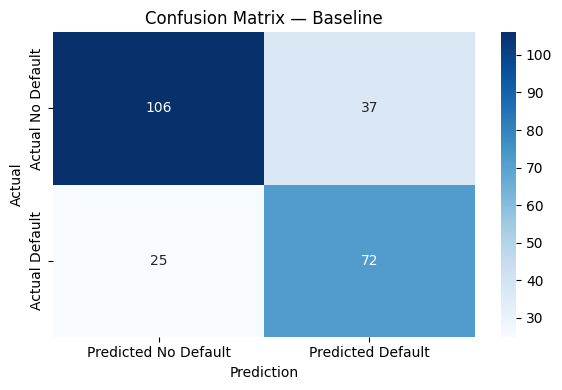

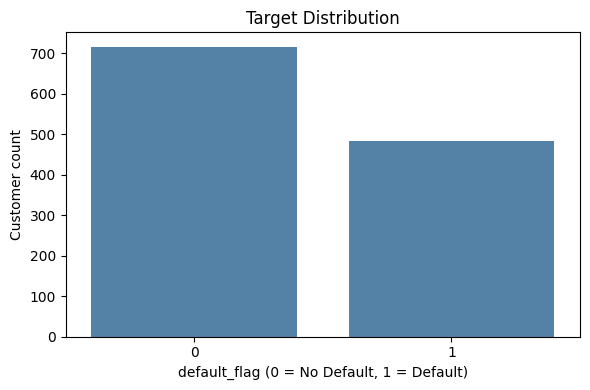

In [10]:
cm = confusion_matrix(y_test, predictions, labels=[0, 1])
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted No Default", "Predicted Default"],
            yticklabels=["Actual No Default", "Actual Default"])
plt.title("Confusion Matrix — Baseline")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
sns.countplot(x=y, color="steelblue")
plt.title("Target Distribution")
plt.xlabel("default_flag (0 = No Default, 1 = Default)")
plt.ylabel("Customer count")
plt.tight_layout()
plt.show()

## 9. Export ML-ready train and test matrices

The fitted transformer creates numeric columns from both numeric and one-hot-encoded categorical features. Train and test matrices use the same learned column order. The fitted pipeline remains the preferred reusable artifact because it includes all preprocessing steps.

In [11]:
fitted_preprocessor = credit_risk_pipeline.named_steps["preprocessor"]
feature_names = fitted_preprocessor.get_feature_names_out()
train_array = fitted_preprocessor.transform(X_train)
test_array = fitted_preprocessor.transform(X_test)

if hasattr(train_array, "toarray"):
    train_array = train_array.toarray()
if hasattr(test_array, "toarray"):
    test_array = test_array.toarray()

train_matrix = pd.DataFrame(train_array, columns=feature_names, index=X_train.index)
test_matrix = pd.DataFrame(test_array, columns=feature_names, index=X_test.index)
train_matrix["default_flag"] = y_train
test_matrix["default_flag"] = y_test
train_matrix.to_csv(DATA_PROCESSED / "day_08_ml_ready_train.csv", index=False)
test_matrix.to_csv(DATA_PROCESSED / "day_08_ml_ready_test.csv", index=False)

print("Train matrix:", train_matrix.shape)
print("Test matrix:", test_matrix.shape)
print("Columns aligned:", list(train_matrix.columns) == list(test_matrix.columns))
display(train_matrix.head())

Train matrix: (960, 41)
Test matrix: (240, 41)
Columns aligned: True


,numeric__age,numeric__annual_income,numeric__loan_amount,numeric__credit_score,numeric__transaction_count,numeric__spending_ratio,numeric__loan_to_income_ratio,numeric__income_per_transaction,numeric__customer_tenure_days,numeric__repayment_risk_level,...,categorical__repayment_history_Excellent,categorical__repayment_history_Fair,categorical__repayment_history_Good,categorical__repayment_history_Poor,categorical__age_band_18-25,categorical__age_band_26-35,categorical__age_band_36-50,categorical__age_band_51-65,categorical__age_band_66+,default_flag
796,1.606801,-0.228747,0.938166,-0.673894,1.107467,0.449580,1.107655,-0.869313,-1.360556,-1.263733,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1
222,0.708093,-0.228747,1.429006,0.738045,-0.517069,2.033032,1.647454,0.104551,0.072435,1.940098,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0
77,-0.951061,-0.228747,-1.449081,0.411731,0.385451,-1.068575,-1.517712,-0.494975,-0.053582,-0.195790,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0
990,-0.536273,-0.228747,0.535498,1.277720,-1.058581,-0.513551,0.664822,0.563498,1.439416,0.872154,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0
93,-0.398010,-0.228747,-0.989591,0.876102,-0.156061,-0.970630,-1.012389,-0.156419,1.115373,0.872154,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0


## 10. Save pipeline and reproducibility metadata

The metadata records feature lists, seed, split size, reference date, and whether the source was synthetic. Only load serialized joblib files from trusted sources.

In [12]:
joblib.dump(credit_risk_pipeline, DATA_PROCESSED / "day_08_credit_risk_pipeline.joblib")
metadata = {
    "project": "Holistic Data Preparer",
    "day": 8,
    "domain": "Fintech",
    "use_case": "Customer Credit Risk Prediction",
    "dataset_status": "SYNTHETIC DEMONSTRATION DATA" if IS_SYNTHETIC_DEMO else "Existing project dataset",
    "source_file": str(dataset_path) if dataset_path else None,
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
    "reference_date": str(REFERENCE_DATE.date()),
    "target": TARGET,
    "identifier_excluded": IDENTIFIER,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "engineered_features": engineered_features,
    "preprocessing": {
        "numeric_imputation": "median",
        "numeric_scaling": "StandardScaler",
        "categorical_imputation": "most_frequent",
        "categorical_encoding": "OneHotEncoder(handle_unknown='ignore')"
    },
    "baseline_model": "LogisticRegression(class_weight='balanced')"
}
(REPORTS / "day_08_run_metadata.json").write_text(json.dumps(metadata, indent=4), encoding="utf-8")
print("Pipeline and metadata saved.")

Pipeline and metadata saved.


## 11. Create reusable Python source code

The function below reproduces the Day 8 feature creation. It returns a copy and does not mutate the caller's DataFrame.

In [13]:
feature_source = '''
import numpy as np
import pandas as pd

REFERENCE_DATE = pd.Timestamp("2026-01-01")

def create_credit_risk_features(data: pd.DataFrame) -> pd.DataFrame:
    # Return a feature-engineered copy; do not mutate the input.
    result = data.copy()
    for column in ["age", "annual_income", "loan_amount", "credit_score",
                   "transaction_count", "spending_ratio"]:
        result[column] = pd.to_numeric(result[column], errors="coerce")

    income = result["annual_income"].where(result["annual_income"] > 0)
    transactions = result["transaction_count"].where(result["transaction_count"] > 0)
    result["loan_to_income_ratio"] = result["loan_amount"] / income
    result["income_per_transaction"] = result["annual_income"] / transactions
    result["customer_tenure_days"] = (
        REFERENCE_DATE - pd.to_datetime(result["join_date"], errors="coerce")
    ).dt.days
    result.loc[result["customer_tenure_days"] < 0, "customer_tenure_days"] = np.nan
    result["age_band"] = pd.cut(
        result["age"], bins=[0, 25, 35, 50, 65, np.inf],
        labels=["18-25", "26-35", "36-50", "51-65", "66+"]
    )
    result["repayment_risk_level"] = result["repayment_history"].map(
        {"Excellent": 0, "Good": 1, "Fair": 2, "Poor": 3}
    )
    return result
'''
(SRC / "feature_engineering.py").write_text(feature_source, encoding="utf-8")
print("Created:", SRC / "feature_engineering.py")

Created: c:\Users\tejpa\OneDrive\Documents\R & W Projects\Data Preparing & Processing\Holistic-data-preparer\src\feature_engineering.py


## 12. Create requirements and delivery notes

In [14]:
requirements_text = (
    "numpy\npandas\nmatplotlib\nseaborn\nscikit-learn\n"
    "jupyter\nipykernel\njoblib\n"
)
(PROJECT_ROOT / "requirements.txt").write_text(requirements_text, encoding="utf-8")

delivery_notes = (
    "# Holistic Data Preparer — Day 8\n\n"
    + "Dataset status: " + ("SYNTHETIC DEMONSTRATION DATA — replace before submission.\n\n"
       if IS_SYNTHETIC_DEMO else "Existing project dataset loaded.\n\n")
    + "## Outputs\n"
    + "- data/processed/day_08_feature_engineered.csv\n"
    + "- data/processed/day_08_ml_ready_train.csv\n"
    + "- data/processed/day_08_ml_ready_test.csv\n"
    + "- data/processed/day_08_credit_risk_pipeline.joblib\n"
    + "- reports/day_08_feature_engineering_report.csv\n"
    + "- reports/day_08_feature_selection_report.csv\n"
    + "- reports/day_08_final_validation_report.csv\n"
    + "- reports/day_08_baseline_model_metrics.csv\n"
    + "- reports/day_08_run_metadata.json\n"
    + "- src/feature_engineering.py\n\n"
    + "The baseline is an educational demonstration, not a lending decision system. "
      "Review data provenance, fairness, privacy, feature timing, and legal requirements."
)
(REPORTS / "DAY_08_DELIVERY_NOTES.md").write_text(delivery_notes, encoding="utf-8")
print("Created requirements.txt and Day 8 delivery notes.")

Created requirements.txt and Day 8 delivery notes.


## 13. Output inventory

In [15]:
expected_outputs = [
    DATA_PROCESSED / "day_08_feature_engineered.csv",
    DATA_PROCESSED / "day_08_ml_ready_train.csv",
    DATA_PROCESSED / "day_08_ml_ready_test.csv",
    DATA_PROCESSED / "day_08_credit_risk_pipeline.joblib",
    DATA_INTERIM / "day_08_train_raw_features.csv",
    DATA_INTERIM / "day_08_test_raw_features.csv",
    REPORTS / "day_08_feature_engineering_report.csv",
    REPORTS / "day_08_feature_selection_report.csv",
    REPORTS / "day_08_final_validation_report.csv",
    REPORTS / "day_08_baseline_model_metrics.csv",
    REPORTS / "day_08_run_metadata.json",
    SRC / "feature_engineering.py",
    PROJECT_ROOT / "requirements.txt"
]
inventory = pd.DataFrame({
    "file": [str(p.relative_to(PROJECT_ROOT)) for p in expected_outputs],
    "exists": [p.exists() for p in expected_outputs],
    "size_bytes": [p.stat().st_size if p.exists() else None for p in expected_outputs]
})
display(inventory)
inventory.to_csv(REPORTS / "day_08_output_inventory.csv", index=False)

,file,exists,size_bytes
0,data\processed\day_08_feature_engineered.csv,True,167495
1,data\processed\day_08_ml_ready_train.csv,True,308921
2,data\processed\day_08_ml_ready_test.csv,True,78242
3,data\processed\day_08_credit_risk_pipeline.joblib,True,6874
4,data\interim\day_08_train_raw_features.csv,True,124527
5,data\interim\day_08_test_raw_features.csv,True,31218
6,reports\day_08_feature_engineering_report.csv,True,384
7,reports\day_08_feature_selection_report.csv,True,677
8,reports\day_08_final_validation_report.csv,True,589
9,reports\day_08_baseline_model_metrics.csv,True,140


## 14. Conclusion

Day 8 completes the data-preparation workflow by creating derived credit-risk features, selecting appropriate predictors, validating the dataset, and preparing a leakage-safe train/test workflow. Imputation, encoding, and scaling are learned only from training data through a scikit-learn pipeline. The notebook exports audit-friendly data, ML-ready matrices, quality reports, metadata, reusable Python source, and the fitted pipeline.

A clean dataset is not automatically a fair, compliant, or production-ready credit-risk system. Validate the data source, target definition, feature timing, fairness, and business costs before real-world use.